In [1]:
import glob
import os
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt





In [3]:
print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

search_dirs = ["/kaggle/input", "/kaggle/working"]

def find_file(filename):
    for directory in search_dirs:
        matches = glob.glob(os.path.join(directory, "**", filename), recursive=True)
        if matches:
            return matches[0]
    raise FileNotFoundError(
        f"{filename} was not found in /kaggle/input or /kaggle/working"
    )

X_train_path = find_file("X_train.npy")
y_train_path = find_file("y_train.npy")
X_val_path = find_file("X_val.npy")
y_val_path = find_file("y_val.npy")

print("Train images:", X_train_path)
print("Train labels:", y_train_path)
print("Validation images:", X_val_path)
print("Validation labels:", y_val_path)

X_train = np.load(X_train_path).astype(np.float32)
y_train = np.load(y_train_path).astype(np.int32)
X_val = np.load(X_val_path).astype(np.float32)
y_val = np.load(y_val_path).astype(np.int32)

print("Train images shape:", X_train.shape)
print("Train labels shape:", y_train.shape)
print("Validation images shape:", X_val.shape)
print("Validation labels shape:", y_val.shape)
print("Pixel range:", X_train.min(), "to", X_train.max())
print("Classes:", np.unique(y_train))

TensorFlow version: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Train images: /kaggle/input/datasets/omarashour206/aptos2019-preprocessed-dataset/X_train.npy
Train labels: /kaggle/input/datasets/omarashour206/aptos2019-preprocessed-dataset/y_train.npy
Validation images: /kaggle/input/datasets/omarashour206/aptos2019-preprocessed-dataset/X_val.npy
Validation labels: /kaggle/input/datasets/omarashour206/aptos2019-preprocessed-dataset/y_val.npy
Train images shape: (4489, 224, 224, 3)
Train labels shape: (4489,)
Validation images shape: (733, 224, 224, 3)
Validation labels shape: (733,)
Pixel range: 0.0 to 1.0
Classes: [0 1 2 3 4]


In [4]:
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def prepare_image(image, label):
    image = tf.cast(image, tf.float32) * 255.0
    label = tf.cast(label, tf.int32)
    return image, label

train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train))
train_ds = (
    train_ds.shuffle(2000)
    .map(prepare_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val))
val_ds = (
    val_ds.map(prepare_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

for images, labels in train_ds.take(1):
    print("Images shape:", images.shape)
    print("Labels shape:", labels.shape)
    print("Pixel range:", tf.reduce_min(images).numpy(), tf.reduce_max(images).numpy())

I0000 00:00:1792223308.358527      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792223308.362153      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Images shape: (32, 224, 224, 3)
Labels shape: (32,)
Pixel range: 0.0 255.0


In [5]:
base_model = keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)
base_model.trainable = False

inputs = keras.Input(shape=(224, 224, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(5, activation="softmax")(x)

model = keras.Model(inputs, outputs)
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,055,976 (15.47 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [6]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        "/kaggle/working/best_efficientnet_b0.keras",
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1,
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True,
        mode="min", verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=2, min_lr=1e-7, verbose=1
    ),
]

history = model.fit(
    train_ds, validation_data=val_ds, epochs=10, callbacks=callbacks
)

Epoch 1/10


2026-10-17 07:49:09.963654: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 07:49:10.106661: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 07:49:10.457278: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 07:49:10.599871: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 07:49:11.425743: E external/local_xla/xla/stream_

140/141 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.3968 - loss: 1.4782

2026-10-17 07:49:29.850842: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 07:49:29.987286: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 07:49:30.305748: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 07:49:30.447716: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 07:49:31.244028: E external/local_xla/xla/stream_

141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step - accuracy: 0.3969 - loss: 1.4781

2026-10-17 07:49:51.498795: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 07:49:51.642767: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 07:49:51.997180: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 07:49:52.139579: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 07:49:52.939809: E external/local_xla/xla/stream_


Epoch 1: val_loss improved from None to 1.55276, saving model to /kaggle/working/best_efficientnet_b0.keras

Epoch 1: finished saving model to /kaggle/working/best_efficientnet_b0.keras
141/141 ━━━━━━━━━━━━━━━━━━━━ 68s 279ms/step - accuracy: 0.4090 - loss: 1.4609 - val_accuracy: 0.4134 - val_loss: 1.5528 - learning_rate: 1.0000e-04
Epoch 2/10
139/141 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.4570 - loss: 1.3879
Epoch 2: val_loss improved from 1.55276 to 1.29826, saving model to /kaggle/working/best_efficientnet_b0.keras

Epoch 2: finished saving model to /kaggle/working/best_efficientnet_b0.keras
141/141 ━━━━━━━━━━━━━━━━━━━━ 6s 45ms/step - accuracy: 0.4830 - loss: 1.2999 - val_accuracy: 0.5020 - val_loss: 1.2983 - learning_rate: 1.0000e-04
Epoch 3/10
139/141 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.5361 - loss: 1.1972
Epoch 3: val_loss improved from 1.29826 to 1.18249, saving model to /kaggle/working/best_efficientnet_b0.keras

Epoch 3: finished saving model to /kaggle/wo

23/23 ━━━━━━━━━━━━━━━━━━━━ 13s 320ms/step
                  precision    recall  f1-score   support

           No DR       0.88      0.95      0.91       361
            Mild       0.57      0.11      0.18        74
        Moderate       0.68      0.28      0.39       200
          Severe       0.22      0.36      0.27        39
Proliferative DR       0.22      0.69      0.34        59

        accuracy                           0.63       733
       macro avg       0.51      0.48      0.42       733
    weighted avg       0.70      0.63      0.62       733



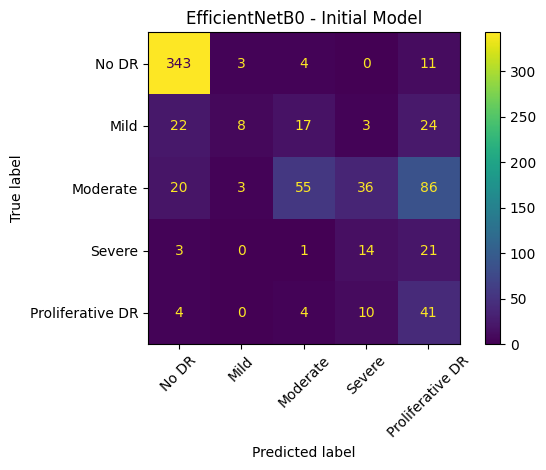

In [7]:

best_model = keras.models.load_model("/kaggle/working/best_efficientnet_b0.keras")
y_prob = best_model.predict(val_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

class_names = ["No DR", "Mild", "Moderate", "Severe", "Proliferative DR"]
print(classification_report(
    y_val, y_pred, labels=[0, 1, 2, 3, 4],
    target_names=class_names, zero_division=0
))

cm = confusion_matrix(y_val, y_pred, labels=[0, 1, 2, 3, 4])
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names).plot(xticks_rotation=45)
plt.title("EfficientNetB0 - Initial Model")
plt.tight_layout()
plt.show()

In [8]:
model_ft = keras.models.load_model("/kaggle/working/best_efficientnet_b0.keras")
base_model_ft = model_ft.get_layer("efficientnetb0")
base_model_ft.trainable = True

for layer in base_model_ft.layers[:-30]:
    layer.trainable = False

for layer in base_model_ft.layers:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False

print("Trainable layers:", sum(layer.trainable for layer in base_model_ft.layers))

model_ft.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

callbacks_ft = [
    keras.callbacks.ModelCheckpoint(
        "/kaggle/working/best_efficientnet_b0_finetuned.keras",
        monitor="val_loss", save_best_only=True, mode="min", verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=2, restore_best_weights=True,
        mode="min", verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=1, min_lr=1e-7, verbose=1
    ),
]

history_ft = model_ft.fit(
    train_ds, validation_data=val_ds, epochs=8, callbacks=callbacks_ft
)

Trainable layers: 23
Epoch 1/8
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step - accuracy: 0.6684 - loss: 0.8256
Epoch 1: val_loss improved from None to 0.85239, saving model to /kaggle/working/best_efficientnet_b0_finetuned.keras

Epoch 1: finished saving model to /kaggle/working/best_efficientnet_b0_finetuned.keras
141/141 ━━━━━━━━━━━━━━━━━━━━ 51s 208ms/step - accuracy: 0.6612 - loss: 0.8227 - val_accuracy: 0.6453 - val_loss: 0.8524 - learning_rate: 1.0000e-05
Epoch 2/8
140/141 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.6938 - loss: 0.7687
Epoch 2: val_loss improved from 0.85239 to 0.81042, saving model to /kaggle/working/best_efficientnet_b0_finetuned.keras

Epoch 2: finished saving model to /kaggle/working/best_efficientnet_b0_finetuned.keras
141/141 ━━━━━━━━━━━━━━━━━━━━ 7s 52ms/step - accuracy: 0.6792 - loss: 0.7761 - val_accuracy: 0.6726 - val_loss: 0.8104 - learning_rate: 1.0000e-05
Epoch 3/8
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.7079 - loss: 0.7442
Epoch 3: va

23/23 ━━━━━━━━━━━━━━━━━━━━ 13s 311ms/step
                  precision    recall  f1-score   support

           No DR       0.94      0.96      0.95       361
            Mild       0.47      0.31      0.37        74
        Moderate       0.74      0.50      0.60       200
          Severe       0.31      0.51      0.39        39
Proliferative DR       0.35      0.68      0.46        59

        accuracy                           0.72       733
       macro avg       0.56      0.59      0.55       733
    weighted avg       0.76      0.72      0.73       733



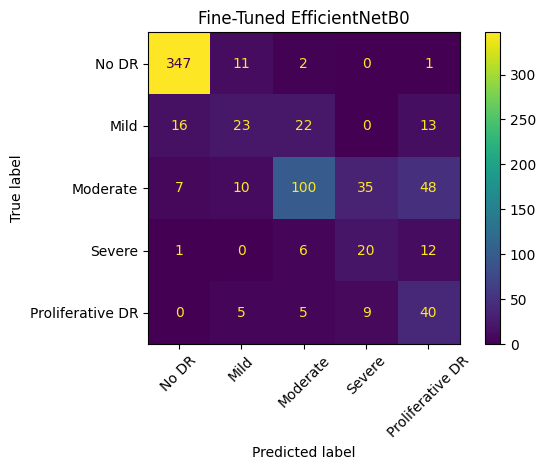

In [9]:
best_ft = keras.models.load_model("/kaggle/working/best_efficientnet_b0_finetuned.keras")
y_prob_ft = best_ft.predict(val_ds, verbose=1)
y_pred_ft = np.argmax(y_prob_ft, axis=1)

print(classification_report(
    y_val, y_pred_ft, labels=[0, 1, 2, 3, 4],
    target_names=class_names, zero_division=0
))

cm = confusion_matrix(y_val, y_pred_ft, labels=[0, 1, 2, 3, 4])
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names).plot(xticks_rotation=45)
plt.title("Fine-Tuned EfficientNetB0")
plt.tight_layout()
plt.show()

In [10]:
print("Training set:")
for i, name in enumerate(class_names):
    print(f"{name}: {np.sum(y_train == i)} images")

print("\nValidation set:")
for i, name in enumerate(class_names):
    print(f"{name}: {np.sum(y_val == i)} images")

Training set:
No DR: 1444 images
Mild: 296 images
Moderate: 799 images
Severe: 770 images
Proliferative DR: 1180 images

Validation set:
No DR: 361 images
Mild: 74 images
Moderate: 200 images
Severe: 39 images
Proliferative DR: 59 images


In [11]:
for layer in model_ft.layers:
    print(layer.name, type(layer).__name__)

input_layer_1 InputLayer
efficientnetb0 Functional
global_average_pooling2d GlobalAveragePooling2D
dropout Dropout
dense Dense


In [12]:
old_model = keras.models.load_model(
    "/kaggle/working/best_efficientnet_b0_finetuned.keras"
)
base_model_new = old_model.get_layer("efficientnetb0")
base_model_new.trainable = False

inputs = keras.Input(shape=(224, 224, 3))
x = base_model_new(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(5, activation="softmax")(x)

model_new = keras.Model(inputs, outputs)
model_new.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model_new.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,378,792 (16.70 MB)

 Trainable params: 329,221 (1.26 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [13]:
callbacks_new = [
    keras.callbacks.ModelCheckpoint(
        "/kaggle/working/best_efficientnet_b0_new_head.keras",
        monitor="val_loss", save_best_only=True, verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True, verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=2, min_lr=1e-7, verbose=1
    ),
]

history_new = model_new.fit(
    train_ds, validation_data=val_ds, epochs=10, callbacks=callbacks_new
)

Epoch 1/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 106ms/step - accuracy: 0.5610 - loss: 1.1130
Epoch 1: val_loss improved from None to 0.82108, saving model to /kaggle/working/best_efficientnet_b0_new_head.keras

Epoch 1: finished saving model to /kaggle/working/best_efficientnet_b0_new_head.keras
141/141 ━━━━━━━━━━━━━━━━━━━━ 46s 195ms/step - accuracy: 0.5894 - loss: 0.9902 - val_accuracy: 0.6548 - val_loss: 0.8211 - learning_rate: 1.0000e-04
Epoch 2/10
139/141 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.7135 - loss: 0.7282
Epoch 2: val_loss improved from 0.82108 to 0.76883, saving model to /kaggle/working/best_efficientnet_b0_new_head.keras

Epoch 2: finished saving model to /kaggle/working/best_efficientnet_b0_new_head.keras
141/141 ━━━━━━━━━━━━━━━━━━━━ 6s 45ms/step - accuracy: 0.6933 - loss: 0.7384 - val_accuracy: 0.6794 - val_loss: 0.7688 - learning_rate: 1.0000e-04
Epoch 3/10
139/141 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.7353 - loss: 0.6641
Epoch 3: val_loss improved from 0

23/23 ━━━━━━━━━━━━━━━━━━━━ 13s 320ms/step
                  precision    recall  f1-score   support

           No DR       0.94      0.96      0.95       361
            Mild       0.50      0.28      0.36        74
        Moderate       0.69      0.64      0.66       200
          Severe       0.34      0.33      0.34        39
Proliferative DR       0.36      0.61      0.46        59

        accuracy                           0.74       733
       macro avg       0.57      0.56      0.55       733
    weighted avg       0.75      0.74      0.74       733



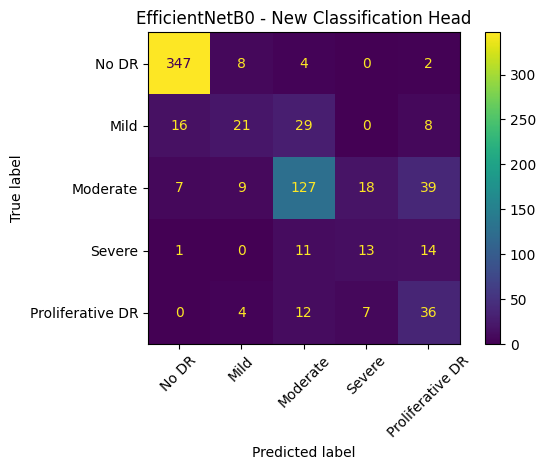

In [14]:
best_new = keras.models.load_model("/kaggle/working/best_efficientnet_b0_new_head.keras")
y_prob_new = best_new.predict(val_ds, verbose=1)
y_pred_new = np.argmax(y_prob_new, axis=1)

print(classification_report(
    y_val, y_pred_new, labels=[0, 1, 2, 3, 4],
    target_names=class_names, zero_division=0
))

cm = confusion_matrix(y_val, y_pred_new, labels=[0, 1, 2, 3, 4])
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names).plot(xticks_rotation=45)
plt.title("EfficientNetB0 - New Classification Head")
plt.tight_layout()
plt.show()

In [26]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

callbacks = [
    ModelCheckpoint(
        "/kaggle/working/best_efficientnet_b0_new_head.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

history_new = model_new.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

Epoch 1/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.7664 - loss: 0.6264
Epoch 1: val_loss improved from None to 0.69217, saving model to /kaggle/working/best_efficientnet_b0_new_head.keras

Epoch 1: finished saving model to /kaggle/working/best_efficientnet_b0_new_head.keras
141/141 ━━━━━━━━━━━━━━━━━━━━ 7s 49ms/step - accuracy: 0.7418 - loss: 0.6494 - val_accuracy: 0.7244 - val_loss: 0.6922 - learning_rate: 5.0000e-05
Epoch 2/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.7580 - loss: 0.6132
Epoch 2: val_loss improved from 0.69217 to 0.68768, saving model to /kaggle/working/best_efficientnet_b0_new_head.keras

Epoch 2: finished saving model to /kaggle/working/best_efficientnet_b0_new_head.keras
141/141 ━━━━━━━━━━━━━━━━━━━━ 7s 51ms/step - accuracy: 0.7431 - loss: 0.6359 - val_accuracy: 0.7217 - val_loss: 0.6877 - learning_rate: 5.0000e-05
Epoch 3/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.7605 - loss: 0.6044
Epoch 3: val_loss did not improve fr

23/23 ━━━━━━━━━━━━━━━━━━━━ 14s 315ms/step
                  precision    recall  f1-score   support

           No DR       0.94      0.96      0.95       361
            Mild       0.54      0.34      0.42        74
        Moderate       0.69      0.67      0.68       200
          Severe       0.37      0.51      0.43        39
Proliferative DR       0.41      0.49      0.45        59

        accuracy                           0.76       733
       macro avg       0.59      0.59      0.59       733
    weighted avg       0.76      0.76      0.75       733



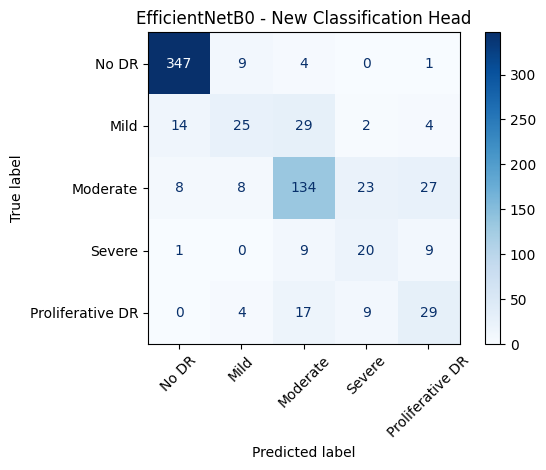

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

best_model = keras.models.load_model(
    "/kaggle/working/best_efficientnet_b0_new_head.keras"
)

y_prob = best_model.predict(val_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

class_names = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative DR"
]

print(classification_report(
    y_val,
    y_pred,
    labels=[0, 1, 2, 3, 4],
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(
    y_val,
    y_pred,
    labels=[0, 1, 2, 3, 4]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(xticks_rotation=45, cmap="Blues")
plt.title("EfficientNetB0 - New Classification Head")
plt.tight_layout()
plt.show()


In [28]:
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau
)

model_ft2 = keras.models.load_model(
    "/kaggle/working/best_efficientnet_b0_new_head.keras"
)

base_model = model_ft2.get_layer("efficientnetb0")
base_model.trainable = True

# Freeze all layers except the last 30
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model_ft2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks = [
    ModelCheckpoint(
        "/kaggle/working/best_efficientnet_b0_final.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=1,
        min_lr=1e-7,
        verbose=1
    )
]

history_ft2 = model_ft2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=callbacks
)

Epoch 1/8
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step - accuracy: 0.7983 - loss: 0.5339
Epoch 1: val_loss improved from None to 0.67809, saving model to /kaggle/working/best_efficientnet_b0_final.keras

Epoch 1: finished saving model to /kaggle/working/best_efficientnet_b0_final.keras
141/141 ━━━━━━━━━━━━━━━━━━━━ 51s 212ms/step - accuracy: 0.7739 - loss: 0.5670 - val_accuracy: 0.7394 - val_loss: 0.6781 - learning_rate: 1.0000e-05
Epoch 2/8
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.7924 - loss: 0.5232
Epoch 2: val_loss improved from 0.67809 to 0.64475, saving model to /kaggle/working/best_efficientnet_b0_final.keras

Epoch 2: finished saving model to /kaggle/working/best_efficientnet_b0_final.keras
141/141 ━━━━━━━━━━━━━━━━━━━━ 7s 52ms/step - accuracy: 0.7748 - loss: 0.5559 - val_accuracy: 0.7490 - val_loss: 0.6447 - learning_rate: 1.0000e-05
Epoch 3/8
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.7959 - loss: 0.5250
Epoch 3: val_loss did not improve from 0.64475



In [31]:

from tensorflow import keras
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau
)

model_exp = keras.models.load_model(
    "/kaggle/working/best_efficientnet_b0_final.keras"
)

base_model = model_exp.get_layer("efficientnetb0")
base_model.trainable = True

for layer in base_model.layers[:-50]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False

model_exp.compile(
    optimizer=keras.optimizers.Adam(learning_rate=5e-6),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks_exp = [
    ModelCheckpoint(
        "/kaggle/working/best_efficientnet_b0_exp50.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=1,
        min_lr=1e-7,
        verbose=1
    )
]

history_exp = model_exp.fit(
    train_ds,
    validation_data=val_ds,
    epochs=12,
    callbacks=callbacks_exp
)


Epoch 1/12
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step - accuracy: 0.8047 - loss: 0.5094
Epoch 1: val_loss improved from None to 0.63719, saving model to /kaggle/working/best_efficientnet_b0_exp50.keras

Epoch 1: finished saving model to /kaggle/working/best_efficientnet_b0_exp50.keras
141/141 ━━━━━━━━━━━━━━━━━━━━ 52s 212ms/step - accuracy: 0.7908 - loss: 0.5265 - val_accuracy: 0.7544 - val_loss: 0.6372 - learning_rate: 5.0000e-06
Epoch 2/12
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.8078 - loss: 0.5056
Epoch 2: val_loss did not improve from 0.63719

Epoch 2: ReduceLROnPlateau reducing learning rate to 2.499999936844688e-06.
141/141 ━━━━━━━━━━━━━━━━━━━━ 7s 46ms/step - accuracy: 0.7997 - loss: 0.5164 - val_accuracy: 0.7599 - val_loss: 0.6399 - learning_rate: 5.0000e-06
Epoch 3/12
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.8021 - loss: 0.5040
Epoch 3: val_loss improved from 0.63719 to 0.63467, saving model to /kaggle/working/best_efficientnet_b0_exp50.keras

Epoc

In [36]:
import numpy as np
from collections import Counter

model = tf.keras.models.load_model(OLD_MODEL_PATH)

for name, X in [
    ("0-1", X_val),
    ("0-255", X_val * 255.0)
]:
    predictions = model.predict(X, batch_size=32, verbose=0)
    predicted_classes = np.argmax(predictions, axis=1)

    accuracy = np.mean(predicted_classes == y_val)

    print(f"\nInput: {name}")
    print(f"Accuracy: {accuracy:.4f}")
    print("Predicted classes:", Counter(predicted_classes))


Input: 0-1
Accuracy: 0.4925
Predicted classes: Counter({np.int64(0): 733})

Input: 0-255
Accuracy: 0.7708
Predicted classes: Counter({np.int64(0): 370, np.int64(2): 190, np.int64(4): 65, np.int64(1): 60, np.int64(3): 48})


In [32]:
import tensorflow as tf

model = tf.keras.models.load_model(
    "/kaggle/working/best_efficientnet_b0_exp50.keras"
)

loss, accuracy = model.evaluate(
    X_val * 255.0,
    y_val,
    batch_size=32,
    verbose=1
)

print(f"Validation Accuracy: {accuracy * 100:.2f}%")
print(f"Validation Loss: {loss:.4f}")

23/23 ━━━━━━━━━━━━━━━━━━━━ 13s 235ms/step - accuracy: 0.7708 - loss: 0.6089
Validation Accuracy: 77.08%
Validation Loss: 0.6089


In [37]:

import os
import tensorflow as tf

OLD_MODEL_PATH = '/kaggle/working/best_efficientnet_b0_exp50.keras'
NEW_MODEL_PATH = '/kaggle/working/best_efficientnet_b0_finetuned.1.keras'

model = tf.keras.models.load_model(OLD_MODEL_PATH)

base_model = None

for layer in model.layers:
    if isinstance(layer, tf.keras.Model):
        base_model = layer
        break

if base_model is None:
    raise ValueError("EfficientNet backbone was not found.")


base_model.trainable = False

for layer in base_model.layers[-50:]:
    if not isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = True


X_train_255 = X_train * 255.0
X_val_255 = X_val * 255.0

print("Training pixel range:",
      X_train_255.min(), X_train_255.max())
print("Validation pixel range:",
      X_val_255.min(), X_val_255.max())

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        NEW_MODEL_PATH,
        monitor='val_accuracy',
        save_best_only=True,
        mode='max',
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

history = model.fit(
    X_train_255,
    y_train,
    validation_data=(X_val_255, y_val),
    epochs=15,
    batch_size=16,
    callbacks=callbacks,
    shuffle=True
)


Training pixel range: 0.0 255.0
Validation pixel range: 0.0 255.0
Epoch 1/15
281/281 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - accuracy: 0.7988 - loss: 0.4997
Epoch 1: val_accuracy improved from None to 0.78035, saving model to /kaggle/working/best_efficientnet_b0_finetuned.1.keras

Epoch 1: finished saving model to /kaggle/working/best_efficientnet_b0_finetuned.1.keras
281/281 ━━━━━━━━━━━━━━━━━━━━ 57s 120ms/step - accuracy: 0.8071 - loss: 0.5003 - val_accuracy: 0.7804 - val_loss: 0.5866 - learning_rate: 1.0000e-05
Epoch 2/15
279/281 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.8148 - loss: 0.4866
Epoch 2: val_accuracy did not improve from 0.78035
281/281 ━━━━━━━━━━━━━━━━━━━━ 9s 30ms/step - accuracy: 0.8133 - loss: 0.4821 - val_accuracy: 0.7776 - val_loss: 0.6064 - learning_rate: 1.0000e-05
Epoch 3/15
279/281 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.8173 - loss: 0.4747
Epoch 3: val_accuracy improved from 0.78035 to 0.78718, saving model to /kaggle/working/best_efficientnet_b0_finet

In [35]:
import numpy as np
from collections import Counter

predictions = model.predict(X_val, batch_size=32, verbose=0)
predicted_classes = np.argmax(predictions, axis=1)

print("Predicted classes:", Counter(predicted_classes))
print("True classes:", Counter(y_val))

Predicted classes: Counter({np.int64(0): 733})
True classes: Counter({np.int64(0): 361, np.int64(2): 200, np.int64(1): 74, np.int64(4): 59, np.int64(3): 39})


In [38]:
import tensorflow as tf

model = tf.keras.models.load_model(
    "/kaggle/working/best_efficientnet_b0_finetuned.1.keras"
)

loss, accuracy = model.evaluate(
    X_val * 255.0,
    y_val,
    batch_size=32,
    verbose=1
)

print(f"Validation Accuracy: {accuracy * 100:.2f}%")
print(f"Validation Loss: {loss:.4f}")

23/23 ━━━━━━━━━━━━━━━━━━━━ 13s 238ms/step - accuracy: 0.8022 - loss: 0.5739
Validation Accuracy: 80.22%
Validation Loss: 0.5739


In [39]:
BACKUP_PATH = "/kaggle/working/DR_EfficientNetB0_80_22_backup.keras"


model.save(BACKUP_PATH)
print("Backup saved:", BACKUP_PATH)


y_prob = model.predict(X_val_255, batch_size=32, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

class_names = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative DR"
]

print(classification_report(
    y_val,
    y_pred,
    labels=[0, 1, 2, 3, 4],
    target_names=class_names,
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_pred, labels=[0, 1, 2, 3, 4]))

Backup saved: /kaggle/working/DR_EfficientNetB0_80_22_backup.keras
23/23 ━━━━━━━━━━━━━━━━━━━━ 13s 317ms/step
                  precision    recall  f1-score   support

           No DR       0.95      0.97      0.96       361
            Mild       0.57      0.46      0.51        74
        Moderate       0.74      0.80      0.77       200
          Severe       0.55      0.41      0.47        39
Proliferative DR       0.48      0.47      0.48        59

        accuracy                           0.80       733
       macro avg       0.66      0.62      0.64       733
    weighted avg       0.79      0.80      0.80       733

Confusion Matrix:
[[350   9   2   0   0]
 [ 13  34  24   1   2]
 [  6  10 160   6  18]
 [  0   1  12  16  10]
 [  0   6  19   6  28]]


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,054,612 (38.36 MB)

 Trainable params: 2,837,909 (10.83 MB)

 Non-trainable params: 1,540,883 (5.88 MB)

 Optimizer params: 5,675,820 (21.65 MB)

23/23 ━━━━━━━━━━━━━━━━━━━━ 13s 321ms/step
Validation accuracy on the currently loaded X_val/y_val: 81.04%
                  precision    recall  f1-score   support

           No DR       0.95      0.96      0.96       361
            Mild       0.53      0.54      0.54        74
        Moderate       0.76      0.82      0.79       200
          Severe       0.54      0.38      0.45        39
Proliferative DR       0.57      0.47      0.52        59

        accuracy                           0.81       733
       macro avg       0.67      0.64      0.65       733
    weighted avg       0.80      0.81      0.81       733



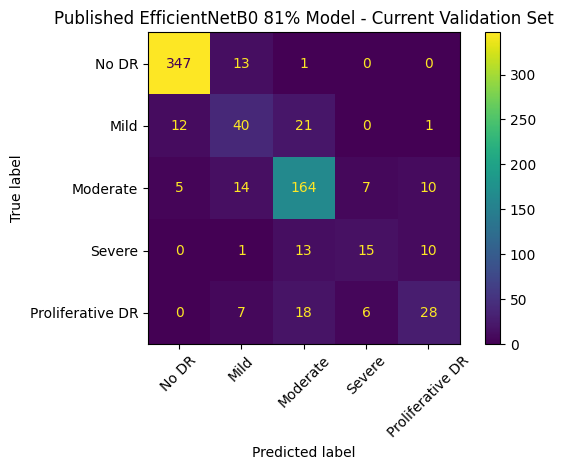

In [42]:
MODEL_PATH = (
    "/kaggle/input/models/omarkhaled67/model-81-accuracy/tensorflow2/default/1/DR_EfficientNetB0_81_percent.keras"
)

if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError(
        "81% model not found at MODEL_PATH. Attach the Kaggle Model via Add Input "
        "and update MODEL_PATH to the actual file path."
    )

model_81 = keras.models.load_model(MODEL_PATH)
model_81.summary()

X_val_input = X_val * 255.0

predictions_81 = model_81.predict(X_val_input, batch_size=32, verbose=1)
y_pred_81 = np.argmax(predictions_81, axis=1)

print("Validation accuracy on the currently loaded X_val/y_val:",
      f"{np.mean(y_pred_81 == y_val) * 100:.2f}%")
print(classification_report(
    y_val, y_pred_81, labels=[0, 1, 2, 3, 4],
    target_names=class_names, zero_division=0
))

cm_81 = confusion_matrix(y_val, y_pred_81, labels=[0, 1, 2, 3, 4])
ConfusionMatrixDisplay(confusion_matrix=cm_81, display_labels=class_names).plot(xticks_rotation=45)
plt.title("Published EfficientNetB0 81% Model - Current Validation Set")
plt.tight_layout()
plt.show()